# First posterior

We have three noisy measurements of an unknown one-dimensional function.
What can we infer about its values between the measurements, where we have
no data? We'll use a Gaussian process to estimate the function on `[-2, 2]`
and show how much uncertainty remains.

Start by enabling 64-bit precision before importing gpex or creating arrays.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp

from gpex import (
    FunctionalBlock,
    FunctionalDataset,
    FunctionalQuery,
    GaussianProcess,
    ObservationBlock,
    kernels,
    operators,
)

## Record the measurements

Two measurements are close together on the left, with a third on the right.
Each row of `x_observed` holds one location. This gives it shape `(3, 1)`,
with one coordinate per location. `y_observed` contains the three measured
function values in the same order.

In [2]:
x_observed = jnp.array([[-1.4], [-1.0], [1.2]])
y_observed = jnp.array([-0.8, -0.5, 0.7])

We assume independent, zero-mean Gaussian measurement errors with variance
`0.02`, or a standard deviation of about `0.14`. This allows the underlying
function values to differ from the readings.

An `ObservationBlock` groups measurements with a shared error variance.
`from_arrays` treats them as function-value measurements by default.
We collect this block in a `FunctionalDataset` and set `max_size=3` to reserve
exactly the three locations used here.

In [3]:
dataset = FunctionalDataset([
    ObservationBlock.from_arrays(
        x_observed, y_observed,
        variance=0.02, name="observed_values", max_size=3,
    )
])

## Choose a prior and condition on the data

The GP prior describes the function before seeing these measurements. We'll
use an RBF kernel, which models smooth functions. Its `lengthscale=0.5`
controls how quickly correlation weakens with distance, so nearby function
values are more closely related than distant ones. Its `variance=1.0` gives
a prior standard deviation of one for the function value at each location.
The default mean is zero.

Conditioning combines this prior with the measurements and their error
variance. The returned posterior describes what we know about the function
after observing the data.

In [4]:
gp = GaussianProcess(
    kernels.RBFKernel(variance=1.0, lengthscale=0.5)
)
posterior = gp.condition(dataset)

## Ask for function values

To see the posterior across the interval, choose a grid of locations and put
it in a `FunctionalQuery`. A `FunctionalBlock` combines those locations with
an operator describing what to evaluate. Here `operators.Identity()` asks for
the function value itself. The name `"function"` lets us retrieve those results.

`predict_marginals` computes a mean and variance at each requested location.
The mean is our estimate of the function value, and the variance measures
our remaining uncertainty about it.

In [5]:
# One coordinate per row, just as for the observed locations.
x = jnp.linspace(-2.0, 2.0, 101)[:, None]
query = FunctionalQuery([
    FunctionalBlock(x, operators.Identity(), name="function"),
])
prediction = posterior.predict_marginals(query)

mean = prediction.mean["function"]
variance = prediction.variance["function"]
standard_deviation = jnp.sqrt(variance)

## Read the posterior

Plot the mean together with a pointwise 95% posterior interval: the mean plus
or minus `1.96` standard deviations at each location. The orange error bars
show the same multiple of the assumed measurement-error standard deviation.

In [6]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.8),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})

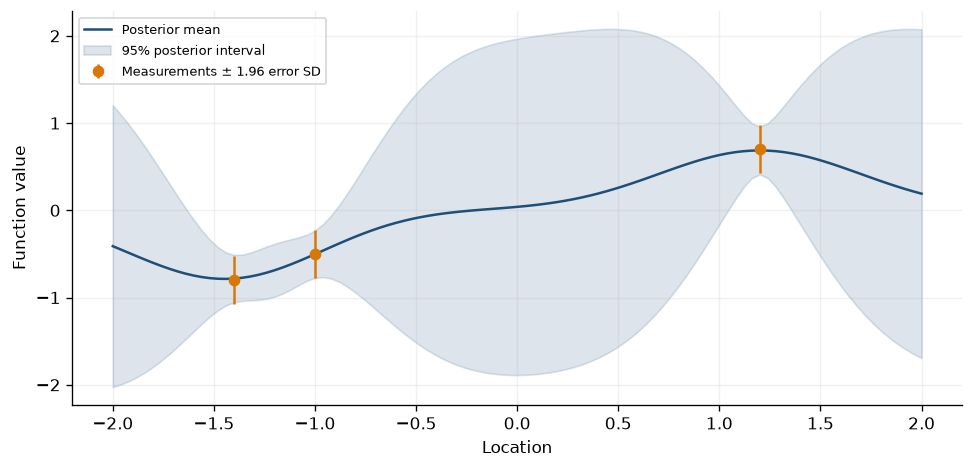

In [7]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(x[:, 0], mean, color="#1F4E79", label="Posterior mean")
ax.fill_between(
    x[:, 0],
    mean - 1.96 * standard_deviation,
    mean + 1.96 * standard_deviation,
    color="#1F4E79", alpha=0.15, label="95% posterior interval",
)
ax.errorbar(
    x_observed[:, 0], y_observed, yerr=1.96 * jnp.sqrt(0.02),
    fmt="o", color="#D97706", label="Measurements ± 1.96 error SD",
)
ax.set(xlabel="Location", ylabel="Function value")
ax.legend(fontsize=8)
plt.show()

The measurements pull the mean toward their values and narrow the uncertainty
nearby. The intervals retain some width even at the measured locations,
because the measurements are noisy.

Across the large gap, the band widens: three measurements leave many possible
function values there. Away from the observations, the mean moves back toward
the prior mean of zero. This behavior follows from our chosen prior, including
its lengthscale.

The blue band describes uncertainty in the underlying function. A future
noisy measurement would have additional measurement uncertainty.

Continue with [Learning a function from derivatives](mixed-measurements.ipynb)
to combine different kinds of measurements, or choose a workflow from the
[tutorial index](index.md).